<sub>**The Annotated ML Handbook** · Part II: NumPy · by Mahir Absar Khan</sub>

# Chapter 9: Computing with NumPy: vectorization, broadcasting, statistics, linear algebra

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-2-numpy/09-numpy-compute.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

With arrays in hand, this chapter covers the operations that do the real work: element-wise maths, broadcasting arrays of different shapes, statistics, random numbers and linear algebra.

## 9.1 Universal functions (ufuncs) · *Beginner*

> **📖 Definitions**
>
> **Ufunc (universal function)**: a NumPy function that operates element by element on whole arrays, such as `np.sqrt`, `np.exp` and `np.log`.


Ufuncs apply a function to every element in compiled code.

**Element-wise maths**

In [2]:
import numpy as np
x = np.array([1.0, 4.0, 9.0, 16.0])
print(x + 1, x * 2, x ** 0.5)
print(np.sqrt(x), np.log(x), np.exp([0, 1]))
print(np.round(np.log10(x), 3))
a, b = np.array([1, 5, 3]), np.array([4, 2, 3])
print(a + b, a * b, a > b, np.maximum(a, b))
print(np.clip(np.array([-2, 0.5, 3]), 0, 1))
print(np.abs([-3, 3]), np.sign([-3, 0, 3]))

[ 2.  5. 10. 17.] [ 2.  8. 18. 32.] [1. 2. 3. 4.]
[1. 2. 3. 4.] [0.         1.38629436 2.19722458 2.77258872] [1.         2.71828183]
[0.    0.602 0.954 1.204]
[5 7 6] [ 4 10  9] [False  True False] [4 5 3]
[0.  0.5 1. ]
[3 3] [-1  0  1]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Import NumPy (the array library) under the short name <code>np</code>.</td></tr>
<tr><td><code>x = np.array([1.0, 4.0, 9.0, 16.0])</code></td><td>Perfect squares, so the square roots are whole numbers.</td></tr>
<tr><td><code>print(x + 1, x * 2, x ** 0.5)</code></td><td>Arithmetic operators work element by element.</td></tr>
<tr><td><code>print(np.sqrt(x), np.log(x), np.exp([0, 1]))</code></td><td>Square root, natural log, exponential.</td></tr>
<tr><td><code>print(np.round(np.log10(x), 3))</code></td><td>log base 10, rounded to 3 decimals.</td></tr>
<tr><td><code>a, b = np.array([1, 5, 3]), np.array([4, 2, 3])</code></td><td>Two arrays of the same shape.</td></tr>
<tr><td><code>print(a + b, a * b, a &gt; b, np.maximum(a, b))</code></td><td>Two arrays of the same shape combine pairwise.</td></tr>
<tr><td><code>print(np.clip(np.array([-2, 0.5, 3]), 0, 1))</code></td><td>Limit values to the range [0, 1].</td></tr>
<tr><td><code>print(np.abs([-3, 3]), np.sign([-3, 0, 3]))</code></td><td>Absolute values; sign gives -1, 0 or +1.</td></tr>
</table>
</details>

> **⚠️ Pitfall** · **`*` is not matrix multiplication**
>
> For arrays, `A * B` multiplies element by element. Matrix multiplication is `A @ B` (or `np.matmul`, `np.dot`).

## 9.2 Broadcasting · *Intermediate*

> **📖 Definitions**
>
> **Broadcasting**: NumPy's rule for combining arrays of different shapes: compare shapes from the right; dimensions must be equal or 1, and size-1 dimensions are stretched to match.


**Broadcasting** lets NumPy combine arrays of different shapes without copying data. Compare the shapes from the **right**; two dimensions are compatible if they are **equal or one of them is 1**. A dimension of 1 is stretched to match.

**Broadcasting in action**

In [3]:
X = np.array([[1, 2, 3],
              [4, 5, 6]])
print(X + 10)
row = np.array([10, 20, 30])
print(X + row)
col = np.array([[100], [200]])
print(X + col)
mu = X.mean(axis=0)
sd = X.std(axis=0)
print((X - mu) / sd)

[[11 12 13]
 [14 15 16]]
[[11 22 33]
 [14 25 36]]
[[101 102 103]
 [204 205 206]]
[[-1. -1. -1.]
 [ 1.  1.  1.]]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>X = np.array([[1, 2, 3],</code></td><td>First row of a (2, 3) array...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[4, 5, 6]])</code></td><td>Shape (2, 3).</td></tr>
<tr><td><code>print(X + 10)</code></td><td>A scalar broadcasts to every element.</td></tr>
<tr><td><code>row = np.array([10, 20, 30])</code></td><td>Shape (3,), treated as (1, 3): stretched down the 2 rows.</td></tr>
<tr><td><code>print(X + row)</code></td><td>Each row gets 10, 20, 30 added.</td></tr>
<tr><td><code>col = np.array([[100], [200]])</code></td><td>Shape (2, 1): stretched across the 3 columns.</td></tr>
<tr><td><code>print(X + col)</code></td><td>Row 1 gets 100 added, row 2 gets 200.</td></tr>
<tr><td><code>mu = X.mean(axis=0)</code></td><td>Column means, shape (3,).</td></tr>
<tr><td><code>sd = X.std(axis=0)</code></td><td>Column standard deviations, shape (3,).</td></tr>
<tr><td><code>print((X - mu) / sd)</code></td><td>Standardise every column in one line: (2,3) op (3,) -&gt; (2,3).</td></tr>
</table>
</details>

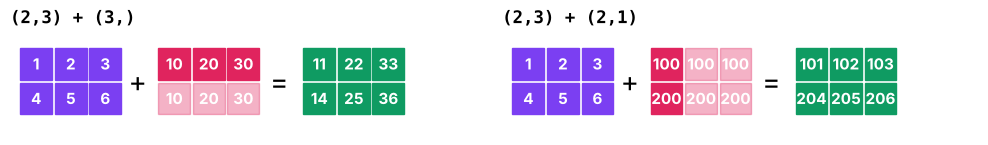

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 2.9))
def grid(ax, x0, vals, color, faded=None, shape=None):
    rows, cols = vals.shape
    for i in range(rows):
        for j in range(cols):
            alpha = 0.35 if (faded is not None and faded[i, j]) else 1
            ax.add_patch(plt.Rectangle((x0 + j, rows - 1 - i), 0.92, 0.92, color=color, alpha=alpha))
            ax.text(x0 + j + 0.46, rows - 1 - i + 0.46, vals[i, j], ha="center", va="center", color="white", fontweight="bold", fontsize=11)
X = np.array([[1, 2, 3], [4, 5, 6]])
for ax, other, label in [(axes[0], np.array([[10, 20, 30]]), "(2,3) + (3,)"), (axes[1], np.array([[100], [200]]), "(2,3) + (2,1)")]:
    ax.set_xlim(-0.3, 13.5); ax.set_ylim(-0.6, 2.4); ax.axis("off"); ax.set_aspect("equal")
    ax.set_title(label, loc="left", family="monospace", fontweight="bold")
    grid(ax, 0, X, "#7b3ff2")
    ax.text(3.4, 0.95, "+", fontsize=20, ha="center", va="center")
    big = np.broadcast_to(other, (2, 3))
    faded = np.ones((2, 3), bool)
    if other.shape == (1, 3): faded[0, :] = False
    else: faded[:, 0] = False
    grid(ax, 4.0, big, "#e0245e", faded)
    ax.text(7.5, 0.95, "=", fontsize=20, ha="center", va="center")
    grid(ax, 8.2, X + big, "#0f9b62")
plt.tight_layout(); plt.show()

**Incompatible shapes**

⚠️ *This cell raises an error **on purpose**, so you can see the real message.*

In [5]:
X = np.ones((2, 3))
v = np.array([1, 2])
X + v

ValueError: operands could not be broadcast together with shapes (2,3) (2,) 

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>X = np.ones((2, 3))</code></td><td>A (2, 3) array of ones.</td></tr>
<tr><td><code>v = np.array([1, 2])</code></td><td>Shape (2,) is compared with X&#x27;s LAST dimension (3): 2 != 3 and neither is 1.</td></tr>
<tr><td><code>X + v</code></td><td>Fix: v[:, np.newaxis] gives shape (2, 1), which broadcasts across columns.</td></tr>
</table>
</details>

> **🐞 Bug hunt** · **`operands could not be broadcast together with shapes (a,b) (c,)`**
>
> Write both shapes one above the other, right-aligned. Every column must be equal or contain a 1. Usually the fix is `arr.reshape(-1, 1)` or `arr[:, None]` to turn a 1-D array into a column.

### 9.2.1 Broadcasting power move: pairwise distances · *Advanced*

**All pairwise Euclidean distances, no loops**

In [6]:
P = np.array([[0, 0], [3, 4], [6, 8]])
diff = P[:, None, :] - P[None, :, :]
D = np.sqrt((diff ** 2).sum(axis=-1))
print(D)

[[ 0.  5. 10.]
 [ 5.  0.  5.]
 [10.  5.  0.]]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>P = np.array([[0, 0], [3, 4], [6, 8]])</code></td><td>3 points in 2-D, shape (3, 2).</td></tr>
<tr><td><code>diff = P[:, None, :] - P[None, :, :]</code></td><td>(3,1,2) - (1,3,2) broadcasts to (3,3,2): every pair&#x27;s difference.</td></tr>
<tr><td><code>D = np.sqrt((diff ** 2).sum(axis=-1))</code></td><td>Square, sum over the coordinate axis, square root -&gt; (3,3) distance matrix.</td></tr>
<tr><td><code>print(D)</code></td><td>This is the heart of k-nearest-neighbours.</td></tr>
</table>
</details>

## 9.3 Statistics and aggregation · *Beginner*

> **📖 Definitions**
>
> **Mean, median, standard deviation**: the mean is the average; the median is the middle value when sorted; the standard deviation (SD) measures how spread out values are around the mean.
>
> **Percentile / quartile**: the value below which a given percentage of observations fall. The quartiles are the 25th, 50th (median) and 75th percentiles.
>
> **Correlation**: a number from −1 to 1 measuring how strongly two variables move together linearly (Pearson's r). 0 means no linear relationship.

**Descriptive statistics**

In [7]:
rng = np.random.default_rng(seed=0)
x = rng.normal(loc=50, scale=10, size=1000)
print(f"mean={x.mean():.2f}  median={np.median(x):.2f}  std={x.std(ddof=1):.2f}")
print(f"min={x.min():.1f} max={x.max():.1f} range={np.ptp(x):.1f}")
print("quartiles:", np.percentile(x, [25, 50, 75]).round(2))
print("cumsum:", np.cumsum([1, 2, 3, 4]))
y = 2 * x + rng.normal(0, 5, size=1000)
print("corr matrix:\n", np.corrcoef(x, y).round(3))

mean=49.52  median=49.25  std=9.77
min=11.0 max=80.7 range=69.7
quartiles: [43.1  49.25 56.15]
cumsum: [ 1  3  6 10]
corr matrix:
 [[1.    0.968]
 [0.968 1.   ]]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>rng = np.random.default_rng(seed=0)</code></td><td>The modern random generator. Always pass a seed for reproducibility.</td></tr>
<tr><td><code>x = rng.normal(loc=50, scale=10, size=1000)</code></td><td>1000 draws from a normal distribution, mean 50, sd 10.</td></tr>
<tr><td><code>print(f&quot;mean={x.mean():.2f}  median={np.median(x):.2f}  std={x.std(ddof=1):.2f}&quot;)</code></td><td>ddof=1 -&gt; sample std (divides by n-1).</td></tr>
<tr><td><code>print(f&quot;min={x.min():.1f} max={x.max():.1f} range={np.ptp(x):.1f}&quot;)</code></td><td>ptp = &quot;peak to peak&quot; = max - min.</td></tr>
<tr><td><code>print(&quot;quartiles:&quot;, np.percentile(x, [25, 50, 75]).round(2))</code></td><td>25th, 50th (median) and 75th percentiles.</td></tr>
<tr><td><code>print(&quot;cumsum:&quot;, np.cumsum([1, 2, 3, 4]))</code></td><td>Running total: [1 3 6 10].</td></tr>
<tr><td><code>y = 2 * x + rng.normal(0, 5, size=1000)</code></td><td>A variable correlated with x.</td></tr>
<tr><td><code>print(&quot;corr matrix:\n&quot;, np.corrcoef(x, y).round(3))</code></td><td>Pearson correlation matrix of the two variables.</td></tr>
</table>
</details>

> **⚠️ Pitfall** · **`np.std` uses ddof=0 by default; pandas uses ddof=1**
>
> NumPy's default divides by *n* (population SD); pandas' `.std()` divides by *n−1* (sample SD). Small samples give noticeably different answers. Be explicit: `np.std(x, ddof=1)`.

## 9.4 Sorting, searching, unique values · *Beginner*

**Order and counts**

In [8]:
a = np.array([3, 1, 4, 1, 5, 9, 2, 6])
print(np.sort(a))
print(np.argsort(a))
print(a[np.argsort(a)[::-1][:3]])
vals, counts = np.unique(a, return_counts=True)
print(vals, counts)
print(np.searchsorted([10, 20, 30], 25))
print(np.argmax(a), np.argmin(a))

[1 1 2 3 4 5 6 9]
[1 3 6 0 2 4 7 5]
[9 6 5]
[1 2 3 4 5 6 9] [2 1 1 1 1 1 1]
2
5 1


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>a = np.array([3, 1, 4, 1, 5, 9, 2, 6])</code></td><td>An unsorted array with a repeated value.</td></tr>
<tr><td><code>print(np.sort(a))</code></td><td>Returns a sorted copy.</td></tr>
<tr><td><code>print(np.argsort(a))</code></td><td>The INDICES that would sort the array: use them to reorder other arrays the same way.</td></tr>
<tr><td><code>print(a[np.argsort(a)[::-1][:3]])</code></td><td>Top-3 values via argsort reversed.</td></tr>
<tr><td><code>vals, counts = np.unique(a, return_counts=True)</code></td><td>Unique values and how often each occurs: class balance at a glance.</td></tr>
<tr><td><code>print(vals, counts)</code></td><td>Each distinct value and its count.</td></tr>
<tr><td><code>print(np.searchsorted([10, 20, 30], 25))</code></td><td>Where 25 would be inserted to keep order: index 2 (binning).</td></tr>
<tr><td><code>print(np.argmax(a), np.argmin(a))</code></td><td>Positions of the largest and the smallest value.</td></tr>
</table>
</details>

## 9.5 Missing values: NaN · *Intermediate*

> **📖 Definitions**
>
> **NaN (not a number)**: a special float value marking a missing or undefined result. Any arithmetic with NaN gives NaN, and NaN is not equal to anything, not even itself.

**Detecting and handling NaN**

In [9]:
d = np.array([1.0, np.nan, 3.0, np.nan, 5.0])
print(d.mean())
print(np.nanmean(d), np.nansum(d), np.nanmax(d))
print(np.isnan(d), np.isnan(d).sum())
print(d[~np.isnan(d)])
print(np.nan_to_num(d, nan=0.0))
print(np.nan == np.nan)

nan
3.0 9.0 5.0
[False  True False  True False] 2
[1. 3. 5.]
[1. 0. 3. 0. 5.]
False


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>d = np.array([1.0, np.nan, 3.0, np.nan, 5.0])</code></td><td>np.nan marks a missing float value.</td></tr>
<tr><td><code>print(d.mean())</code></td><td>Any NaN poisons ordinary aggregates: result is nan.</td></tr>
<tr><td><code>print(np.nanmean(d), np.nansum(d), np.nanmax(d))</code></td><td>The nan-functions ignore missing values.</td></tr>
<tr><td><code>print(np.isnan(d), np.isnan(d).sum())</code></td><td>Detect missing values and count them.</td></tr>
<tr><td><code>print(d[~np.isnan(d)])</code></td><td>Drop them using a negated mask.</td></tr>
<tr><td><code>print(np.nan_to_num(d, nan=0.0))</code></td><td>Replace them with a fixed value.</td></tr>
<tr><td><code>print(np.nan == np.nan)</code></td><td>NaN is not equal to anything, not even itself! Always use np.isnan().</td></tr>
</table>
</details>

## 9.6 Random numbers · *Beginner*

**The Generator API (use this, not np.random.seed)**

In [10]:
rng = np.random.default_rng(42)
print(rng.random(3))
print(rng.integers(0, 10, size=5))
print(rng.normal(0, 1, size=(2, 3)).round(2))
print(rng.choice(["A", "B", "C"], size=5, p=[0.6, 0.3, 0.1]))
idx = rng.permutation(10)
print(idx)

[0.77395605 0.43887844 0.85859792]
[0 6 2 0 5]
[[ 0.13 -0.32 -0.02]
 [-0.85  0.88  0.78]]
['B' 'B' 'A' 'A' 'A']
[6 1 2 7 9 5 8 4 0 3]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>rng = np.random.default_rng(42)</code></td><td>One generator object, seeded once, used everywhere.</td></tr>
<tr><td><code>print(rng.random(3))</code></td><td>Uniform floats in [0, 1).</td></tr>
<tr><td><code>print(rng.integers(0, 10, size=5))</code></td><td>Integers in [0, 10): the high end is excluded.</td></tr>
<tr><td><code>print(rng.normal(0, 1, size=(2, 3)).round(2))</code></td><td>Standard normal values in a 2x3 array.</td></tr>
<tr><td><code>print(rng.choice([&quot;A&quot;, &quot;B&quot;, &quot;C&quot;], size=5, p=[0.6, 0.3, 0.1]))</code></td><td>Weighted random choice.</td></tr>
<tr><td><code>idx = rng.permutation(10)</code></td><td>A shuffled copy of 0..9: the basis of random train/test splits.</td></tr>
<tr><td><code>print(idx)</code></td><td>Display the value of <code>idx</code>.</td></tr>
</table>
</details>

> **💡 Tip** · **Old vs new random API**
>
> Older tutorials use `np.random.seed(0)` and `np.random.rand(...)`. That still works, but NumPy recommends `rng = np.random.default_rng(seed)` and calling methods on `rng`. It is faster, statistically better, and avoids hidden global state.

## 9.7 Linear algebra · *Intermediate*

> **📖 Definitions**
>
> **Matrix multiplication**: combining two matrices by taking dot products of rows of the first with columns of the second; written `A @ B`. Requires `A.shape[1] == B.shape[0]`.
>
> **Eigenvalue / eigenvector**: for a square matrix A, an eigenvector v keeps its direction when multiplied by A: Av = λv, where λ is the eigenvalue. The basis of PCA.

**Matrix operations ML is built on**

In [11]:
A = np.array([[2.0, 1.0],
              [1.0, 3.0]])
b = np.array([3.0, 5.0])
print(A @ b)
print(A @ A)
print(np.linalg.det(A))
x = np.linalg.solve(A, b)
print(x, np.allclose(A @ x, b))
vals, vecs = np.linalg.eigh(A)
print(vals.round(4))
print(np.linalg.norm([3, 4]))
U, S, Vt = np.linalg.svd(np.arange(6).reshape(2, 3).astype(float))
print(S.round(4))

[11. 18.]
[[ 5.  5.]
 [ 5. 10.]]
5.000000000000001
[0.8 1.4] True
[1.382 3.618]
5.0
[7.3485 1.    ]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>A = np.array([[2.0, 1.0],</code></td><td>A 2x2 symmetric matrix: first row...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.0, 3.0]])</code></td><td>...second row.</td></tr>
<tr><td><code>b = np.array([3.0, 5.0])</code></td><td>Right-hand side of the system A x = b.</td></tr>
<tr><td><code>print(A @ b)</code></td><td>Matrix-vector product.</td></tr>
<tr><td><code>print(A @ A)</code></td><td>Matrix-matrix product (rows of the first times columns of the second).</td></tr>
<tr><td><code>print(np.linalg.det(A))</code></td><td>Determinant: about 5 (non-zero, so A is invertible).</td></tr>
<tr><td><code>x = np.linalg.solve(A, b)</code></td><td>Solve Ax = b. More accurate and faster than computing inv(A) @ b.</td></tr>
<tr><td><code>print(x, np.allclose(A @ x, b))</code></td><td>Verify the solution; <code>allclose</code> compares floats with a tolerance.</td></tr>
<tr><td><code>vals, vecs = np.linalg.eigh(A)</code></td><td>Eigen-decomposition of a symmetric matrix (the maths behind PCA).</td></tr>
<tr><td><code>print(vals.round(4))</code></td><td>The two eigenvalues.</td></tr>
<tr><td><code>print(np.linalg.norm([3, 4]))</code></td><td>Euclidean length of a vector: 5.0.</td></tr>
<tr><td><code>U, S, Vt = np.linalg.svd(np.arange(6).reshape(2, 3).astype(float))</code></td><td>Singular value decomposition.</td></tr>
<tr><td><code>print(S.round(4))</code></td><td>The singular values, largest first.</td></tr>
</table>
</details>

**Inner dimensions must agree**

⚠️ *This cell raises an error **on purpose**, so you can see the real message.*

In [12]:
A = np.ones((3, 2))
B = np.ones((3, 2))
A @ B

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 2)

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>A = np.ones((3, 2))</code></td><td>Shape (3, 2).</td></tr>
<tr><td><code>B = np.ones((3, 2))</code></td><td>Also (3, 2): the inner dimensions (2 and 3) don&#x27;t match.</td></tr>
<tr><td><code>A @ B</code></td><td>(3,2) @ (3,2): inner dims 2 and 3 differ. A @ B.T works: (3,2) @ (2,3) -&gt; (3,3).</td></tr>
</table>
</details>

> **✍️ Try it yourself**
>
> 1. Min-max scale each column of a random `(100, 4)` matrix to [0, 1] using broadcasting.
> 2. Using `np.unique(..., return_counts=True)`, report the class proportions of `rng.choice([0, 1], 500, p=[.8, .2])`.
> 3. Solve the system 3x + 2y = 7, x − y = −1 with `np.linalg.solve`.
>
> *Worked solutions:* [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 9*.

---

⬅️ [Chapter 8: NumPy arrays: shape, dtype and indexing](08-numpy-arrays.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 10: Machine learning from scratch with NumPy](10-numpy-ml-scratch.ipynb) ➡️